<a href="https://colab.research.google.com/github/Tysenxw/inst414-Module-Assignments/blob/main/Wills%2C_Module_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

import pandas as pd
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

# Load the Spotify data
df = pd.read_csv("high_popularity_spotify_data.csv")

print("Original dataset size:", df.shape)

# Remove dupe songs
df = df.drop_duplicates(subset=["track_name", "track_artist"])

# collect clustering features
features = ["energy", "danceability", "tempo", "loudness", "valence"]

# Remove songs with null audio values
df = df.dropna(subset=features).copy()

print("cleaned dataset size:", df.shape)

# Scale the features for comparison
scaler = StandardScaler()
scaled_features = scaler.fit_transform(df[features])

# Compare different numbers of clusters
print("\nSilhouette scores for different cluster numbers:")

for k in range(2, 11):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(scaled_features)

    score = silhouette_score(scaled_features, labels)

    print("Clusters:", k, "| Silhouette score:", round(score, 3))

# Group the songs into two clusters
number_of_clusters = 2

model = KMeans(
    n_clusters=number_of_clusters,
    random_state=42,
    n_init=10
)

df["cluster"] = model.fit_predict(scaled_features)

# Find the average audio features in each cluster
print("\naverage audio features for each cluster:")

cluster_averages = df.groupby("cluster")[features].mean().round(3)
cluster_averages.insert(
    0, "number_of_songs", df.groupby("cluster").size()
)

print(cluster_averages)

# Display ten example songs from each cluster
print("example songs from each cluster:")

for cluster in range(number_of_clusters):
    songs = df[df["cluster"] == cluster]

    print("Cluster", cluster, "| Number of songs:", len(songs))

    print(
        songs[["track_name", "track_artist"] + features]
        .head(10)
        .to_string(index=False)
    )

# Save the results to a new CSV file
df.to_csv("clustered_spotify_data.csv", index=False)

print("Results saved to clustered_spotify_data.csv")


Original dataset size: (1686, 29)
cleaned dataset size: (1420, 29)

Silhouette scores for different cluster numbers:
Clusters: 2 | Silhouette score: 0.279
Clusters: 3 | Silhouette score: 0.22
Clusters: 4 | Silhouette score: 0.205
Clusters: 5 | Silhouette score: 0.203
Clusters: 6 | Silhouette score: 0.195
Clusters: 7 | Silhouette score: 0.188
Clusters: 8 | Silhouette score: 0.189
Clusters: 9 | Silhouette score: 0.175
Clusters: 10 | Silhouette score: 0.177

average audio features for each cluster:
         number_of_songs  energy  danceability    tempo  loudness  valence
cluster                                                                   
0                   1054   0.741         0.683  122.769    -5.581    0.598
1                    366   0.438         0.561  117.121   -10.373    0.321
example songs from each cluster:
Cluster 0 | Number of songs: 1054
                   track_name              track_artist  energy  danceability   tempo  loudness  valence
             Die With A Smi

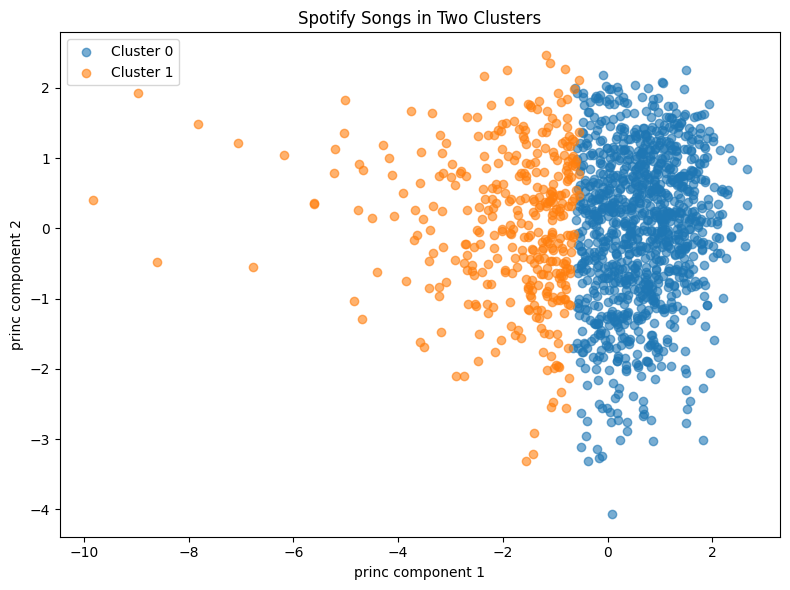

In [ ]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

# scale to two dimensions
pca = PCA(n_components=2)
pca_features = pca.fit_transform(scaled_features)

# Create the scatter plot
plt.figure(figsize=(8, 6))

for cluster in range(2):
    # assigning clusters
    songs = pca_features[df["cluster"].values == cluster]

    plt.scatter(
        songs[:, 0],
        songs[:, 1],
        label=f"Cluster {cluster}",
        alpha=0.6
    )

plt.xlabel("princ component 1")
plt.ylabel("princ component 2")
plt.title("Spotify Songs in Two Clusters")
plt.legend()
plt.tight_layout()

plt.show()